In [1]:
import os
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import pylake

/home/leroquan@eawag.wroot.emp-eaw.ch/miniconda3/envs/horizontal_structures/lib/python3.11/site-packages/pylake/pylake.py:3: UserWarning: The seawater library is deprecated! Please use gsw instead.
  import seawater as sw


In [2]:
lake = 'zug'
folder_path = rf"/storage/alplakes_test/{lake}_100m_2025"
input_folder = os.path.join(folder_path, "outputs_swirl", "eddy_catalogues_final")

In [3]:
date_range = [pd.to_datetime('2025-03-01'), pd.to_datetime('2026-03-01')]

In [4]:
def set_default_figure_setting():
    plt.rcParams.update({
        "figure.figsize": (10, 2),
        "font.family": "serif",
        "font.serif": ["DejaVu Serif"],
        "axes.grid": False,
        "axes.edgecolor": "#8B8B8B",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.minor.visible": False,
        "ytick.minor.visible": False,
    })

set_default_figure_setting()

In [5]:
colors = sns.color_palette("colorblind", 15)
colors

[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784),
 (0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844)]

In [6]:
colors = [color for i, color in enumerate(colors) if i not in [3,5,8]]

# Import catalogue

In [7]:
df_lake = pd.read_csv(os.path.join(input_folder, "lake_characteristics.csv"))
df_lake = df_lake.set_index('id', drop=False)
df_lake['date'] = pd.to_datetime(df_lake['date'])
df_lake = df_lake[df_lake['date'] >= date_range[0]]

In [8]:
df_lvl1 = pd.read_csv(os.path.join(input_folder, "lvl1.csv"))
df_lvl1 = df_lvl1.set_index('id', drop=False)
df_lvl1['date'] = pd.to_datetime(df_lvl1['date'])
df_lvl1 = df_lvl1[(df_lvl1['date'] >= date_range[0]) & (df_lvl1['date'] < date_range[1])]

In [9]:
lake_mask = np.load(os.path.join(folder_path, "grid", "mask_lake.npy"))
depths = pd.read_csv(os.path.join(folder_path, "grid", "depths.csv"))

# Number of eddies

In [10]:
def filter_by_depths(df, depth_min, depth_max):
    depth_filter = (
            (abs(df['depth_min_[m]']) >= abs(depth_max)) &
            (abs(df['depth_max_[m]']) <= abs(depth_min))
    )

    return df[depth_filter]

In [11]:
def display_eddy_numbers_per_depth(ax, depths, colors, df_lvl1):
    for depth_range, color in zip(depths, colors):
        df_filtered = filter_by_depths(df_lvl1, -depth_range[1], -depth_range[0]).copy()
        nb_eddy = df_filtered.groupby(['date'])['id'].count()
        weekly = nb_eddy.resample("1W").mean()
        ax.plot(
            weekly.index.to_pydatetime(),
            weekly,
            lw=1,
            color=color,
            label=f"{depth_range[0]}–{depth_range[1]} m",
        )

    plt.ylim(bottom=0)
    plt.ylabel("Number of eddies")
    plt.legend(title="Depth range", loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
    plt.xlabel("")

    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

In [12]:
df_filtered = filter_by_depths(df_lvl1, -15, -5).copy()
df_filtered = df_filtered[df_filtered['date'] > pd.to_datetime('2025-05-01')]
df_filtered = df_filtered[df_filtered['date'] < pd.to_datetime('2025-09-01')]
nb_eddy = df_filtered.groupby(['date'])['id'].count()
mean_value = nb_eddy.mean()
print(mean_value)

59.545731707317074


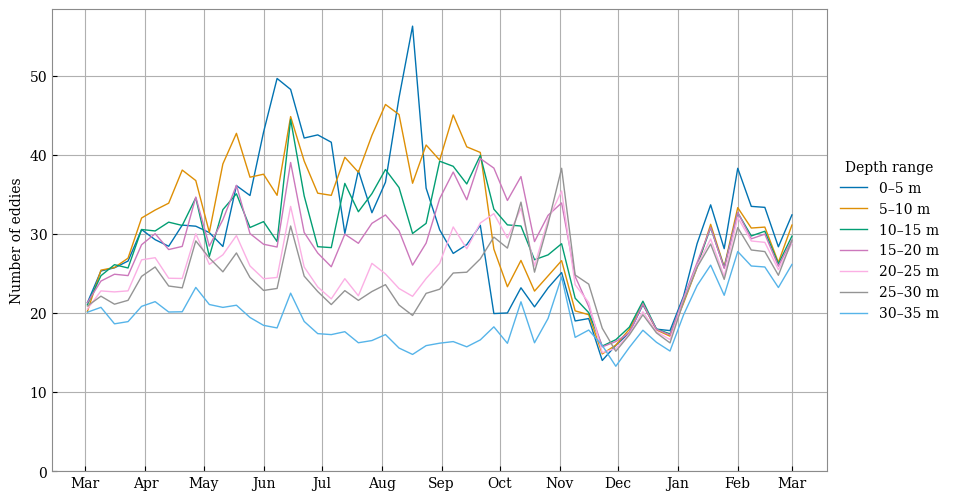

In [44]:
fig, ax = plt.subplots(figsize=(10, 6))
depths = [(0,5), (5,10), (10,15), (15,20), (20,25), (25,30), (30,35)]
display_eddy_numbers_per_depth(ax, depths, colors, df_lvl1)
plt.grid()
#plt.ylim(20,30)

# Import Wind

In [14]:
wind_folder = os.path.join(folder_path, 'wind_analysis')

In [16]:
ds_wind = xr.open_dataset(os.path.join(wind_folder, "wind_stats.nc"))
ds_wind = ds_wind.sel(
    time=(ds_wind.time >= pd.Timestamp(date_range[0]))
         & (ds_wind.time < pd.Timestamp(date_range[1]))
)

In [17]:
def display_wind_speed(ax, ds_wind):
    ds_wind.speed.isel(zone=0).plot(ax=ax, color="#8B8B8B", lw=1)

    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.set_ylabel("Wind Speed [m/s]")
    ax.set_xlabel("")
    ax.set_title('')


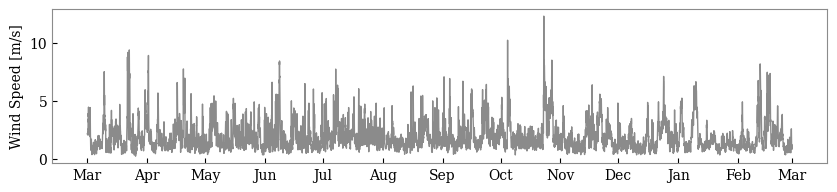

In [18]:
fig, ax = plt.subplots(figsize=(10, 2))
display_wind_speed(ax, ds_wind)

In [19]:
def get_wind_direction_stat(ds_wind):
    # Convert zone 0 to a DataFrame (assuming the time dimension is "time")
    df = (
        ds_wind.direction_cardinal.isel(zone=0)
        .to_series()
        .rename("direction")
        .reset_index()
    )

    # Exclude missing directions
    directions = ["N", "E", "S", "W"]
    df = df[df["direction"].isin(directions)]
    df["month"] = df["time"].dt.to_period("M")

    # Monthly counts and percentages
    counts = (
        pd.crosstab(df["month"], df["direction"])
        .reindex(columns=directions, fill_value=0)
        .sort_index()
    )
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100

    ###
    # Position each bar at the middle of its month
    month_start = percentages.index.to_timestamp()
    month_end = (percentages.index + 1).to_timestamp()
    month_middle = month_start + (month_end - month_start) / 2
    bar_width = (month_end - month_start).days * 0.8

    return percentages, directions, month_start, month_middle, month_end, bar_width

In [20]:
percentages, directions, month_start, month_middle, month_end, bar_width = get_wind_direction_stat(ds_wind)

In [21]:
def display_wind_direction_bar_chart(ax, percentages, directions, month_middle, bar_width):
    bottom = np.zeros(len(percentages))
    for direction, color in zip(directions, colors[:4]):
        values = percentages[direction].to_numpy()

        ax.bar(
            month_middle,
            values,
            bottom=bottom,
            width=bar_width,
            color=color,
            label=direction,
        )
        bottom += values

    ax.set_xlabel("")
    ax.set_ylabel("Frequency [%]")
    ax.set_ylim(0, 100)
    ax.legend(title="Wind Direction", loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
    ax.grid(axis="y", alpha=0.3)

    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=15))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_axisbelow(True)
    ax.set_xlim(month_start[0], month_end[-1])

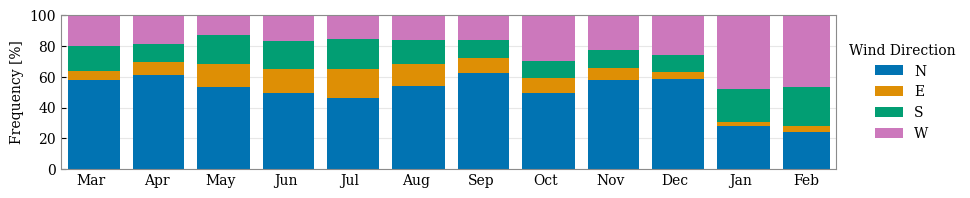

In [22]:
fig, ax = plt.subplots(figsize=(10, 2))
display_wind_direction_bar_chart(ax, percentages, directions, month_middle, bar_width)

# Thermocline depth

In [23]:
xr_lake_temp = df_lake[(
        (df_lake['depth_index'] <= 35) &
        (df_lake['depth_index'] >= 0) &
        (df_lake['date'] >= '2025-03-01') &
        (df_lake['date'] <= '2026-03-01')
    )].groupby(['date','depth_[m]'])['mean_temperature_lake_[°C]'].mean().to_xarray()
xr_lake_temp = xr_lake_temp.rename({'depth_[m]': 'Z'})

In [24]:
thermocline_depth, thermocline_idx = pylake.thermocline(xr_lake_temp.values, -1*xr_lake_temp.Z.values)
thermocline = thermocline_depth.rename({"time": "date"})
thermocline = thermocline.assign_coords(date=xr_lake_temp.date)
thermocline = thermocline.fillna(0)

In [25]:
def display_thermocline(ax, thermocline):
    thermocline.plot(ax=ax, color="#4F4F4F", lw=1, label='Thermocline')

    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.tick_params(axis='both', which='both', direction='in')
    ax.set_ylabel("Depth [m]")
    ax.invert_yaxis()  # Invert y-axis to have depth increasing downwards
    ax.set_xlabel("")
    ax.set_title('')

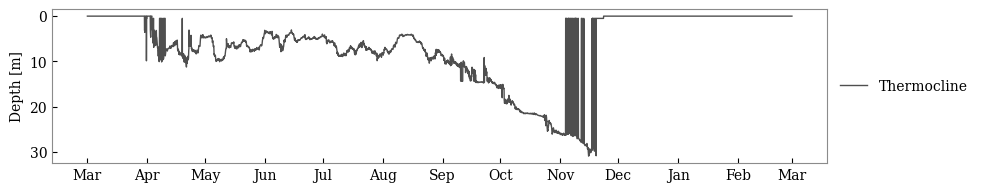

In [26]:
fig, ax = plt.subplots(figsize=(10, 2))
display_thermocline(ax, thermocline)

# Stacked figures

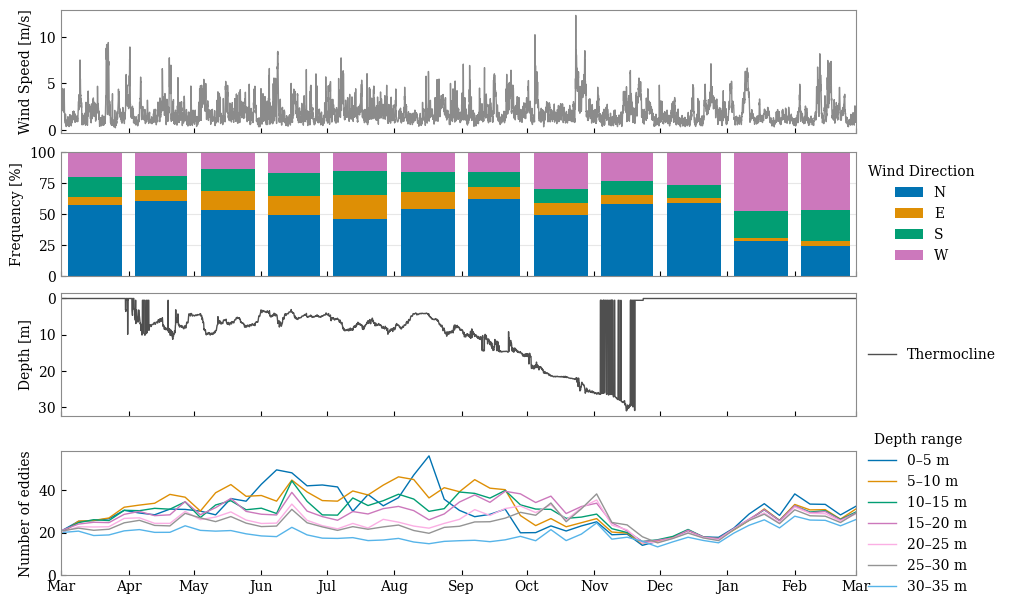

In [45]:
fig, axs = plt.subplots(
    4, 1,
    figsize=(10, 6),
    sharex=True,
    layout="constrained",
)

# Hourly wind speed
display_wind_speed(axs[0], ds_wind)

# Monthly wind directions
display_wind_direction_bar_chart(axs[1], percentages, directions, month_middle, bar_width)

# Thermocline depth
display_thermocline(axs[2], thermocline)

# Eddy numbers per depth
display_eddy_numbers_per_depth(axs[3], depths, colors, df_lvl1)

plt.show()

In [194]:
raise RuntimeError("Stop execution here")

RuntimeError: Stop execution here

# OLD !!

# Surface area

In [ ]:
df_lvl0 = pd.read_csv(os.path.join(input_folder, "lvl0.csv"))
df_lvl0 = df_lvl0.set_index('id', drop=False)
df_lvl0['date'] = pd.to_datetime(df_lvl0['date'])
df_lvl0 = df_lvl0[df_lvl0['date'] >= date_range[0]]

In [ ]:
xr_surface_lake = df_lake[(
        (df_lake['depth_[m]'] <= depth_max) &
        (df_lake['depth_[m]'] >= depth_min) &
        (df_lake['date'] >= '2025-03-01') &
        (df_lake['date'] <= '2026-03-01')
    )].copy().groupby(['date','depth_[m]'])['surface_area_[m2]'].sum().to_xarray()

In [ ]:
xr_surface_eddy = df_lvl0[(
        (df_lvl0['depth_[m]'] <= depth_max) &
        (df_lvl0['depth_[m]'] >= depth_min) &
        (df_lvl0['date'] >= '2025-03-01') &
        (df_lvl0['date'] <= '2026-03-01')
    )].groupby(['date','depth_[m]'])['surface_area_[m2]'].sum().to_xarray()

In [ ]:
xr_surface_eddy = xr_surface_eddy.rename({'depth_[m]': 'Z'})
xr_surface_lake = xr_surface_lake.rename({'depth_[m]': 'Z'})

In [ ]:
xr_surface_ratio = 100 * xr_surface_eddy / xr_surface_lake

(np.float64(20270.0), np.float64(20423.0))

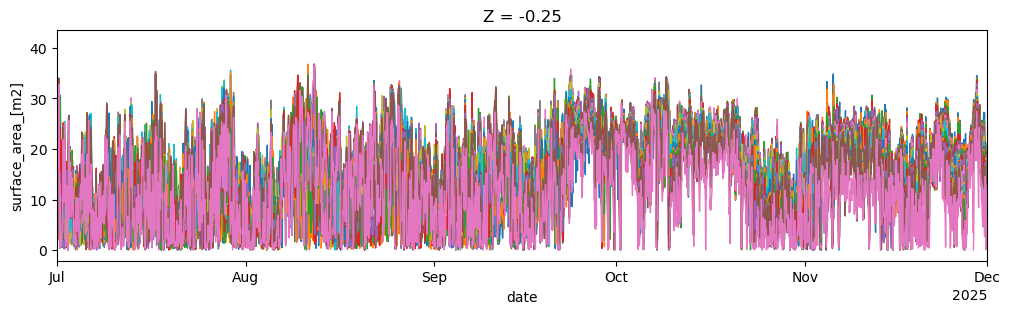

In [ ]:
plt.figure(figsize=(12,3))
for zz in range(len(xr_surface_ratio.Z)):
    xr_surface_ratio.isel(Z=zz).plot(lw=1)

plt.xlim(pd.to_datetime('2025-07-01'),pd.to_datetime('2025-12-01'))

In [ ]:
ts_surface_ratio = xr_surface_ratio.mean(dim='Z')

In [ ]:
annual_mean = 100 * xr_surface_eddy.mean(dim=['Z']).sum().item() / xr_surface_lake.mean(dim=['Z']).sum().item()

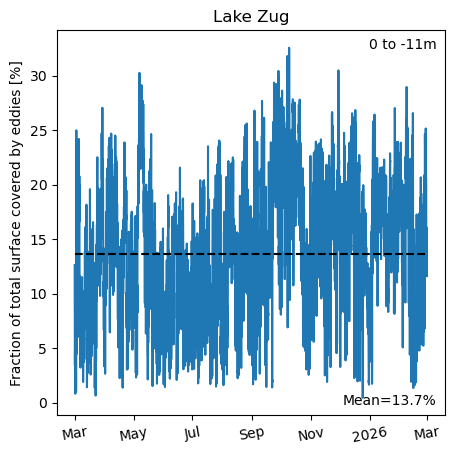

In [ ]:
plt.figure(figsize=(5,5))
ts_surface_ratio.plot()
plt.hlines(annual_mean,
           np.datetime64('2025-03-01'),
           np.datetime64('2026-03-01'),
           linestyles='dashed',
           color='black')

plt.text(0.98,0.02,f'Mean={annual_mean:.1f}%', transform=plt.gca().transAxes, ha='right', va='bottom')
plt.text(0.98, 0.98, f'{depth_max} to {depth_min}m', transform=plt.gca().transAxes, ha='right', va='top')

plt.title(f'Lake {lake.capitalize()}')
plt.ylabel('Fraction of total surface covered by eddies [%]')
plt.xlabel('')
plt.xticks(rotation=10)
plt.grid(False)

# Figure

In [ ]:
numbering=''
add_left_ylabel=True
add_xlabel=True
if lake=='zug':
    numbering='a)'
    add_xlabel=False
if lake=='lucerne':
    numbering='b)'
    add_xlabel=False
    add_left_ylabel=False
if lake=='neuchatel':
    numbering='c)'
if lake=='geneva':
    numbering='d)'
    add_left_ylabel=False

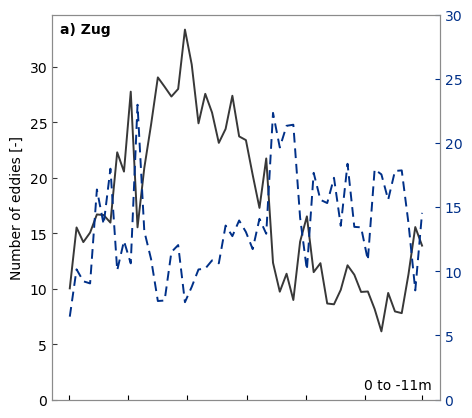

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))

nb_eddy_weekly = nb_eddy_by_depth.resample('1W').mean()
ax.plot(
    nb_eddy_weekly.index,
    nb_eddy_weekly.values,
    color="#383838",
    lw=1.4,
    zorder=2
)

plt.ylim(bottom=0)    
plt.text(0.02, 0.98, f'{numbering} {lake.capitalize()}', transform=plt.gca().transAxes, ha='left', va='top', fontweight='bold')
plt.text(0.98, 0.02, f'{depth_max} to {depth_min}m', transform=plt.gca().transAxes, ha='right', va='bottom')


# --- Second y-axis: eddy surface ratio ---
ax2 = ax.twinx()

surface_ratio_weekly = (
    ts_surface_ratio
    .resample(date='1W')
    .mean()
)
ax2.plot(
    surface_ratio_weekly.date,
    surface_ratio_weekly,
    color="#003088",
    lw=1.4,
    linestyle=(0, (5, 3)),
    zorder=3
)


if add_left_ylabel:
    ax.set_ylabel("Number of eddies [-]")
    ax2.set_ylabel('')    
else:
    ax.set_ylabel('')    
    ax2.set_ylabel("Eddy surface ratio [%]", color="#003088")

ax.tick_params(axis='y', direction='in', color="#383838")
ax2.tick_params(axis='y', direction='in', colors="#003088")
ax2.set_ylim(0,30)

ax.tick_params(axis='x', which='both', labelbottom=add_xlabel, direction='in')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

ax2.tick_params(axis='x', which='both', labelbottom=add_xlabel, direction='in')
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

plt.xlabel("")

# Same publication-style spine
for spine in ax2.spines.values():
    spine.set_color('#8B8B8B')
    spine.set_linewidth(0.8)

for spine in ax.spines.values():
    spine.set_color('#8B8B8B')
    spine.set_linewidth(0.8)

# Surface covered vs total KE 

In [ ]:
df_lake_filtered_by_depth = df_lake[(df_lake['depth_[m]']>depth_min)&(df_lake['depth_[m]']<depth_max)]

In [ ]:
ke_by_depth = df_lake_filtered_by_depth.groupby(['date'])['kinetic_energy_[MJ]'].sum()

In [ ]:
ke_by_depth.values

array([618.73674891, 651.50967133, 777.83010496, ..., 215.60168604,
       207.43164675, 198.89320293], shape=(8760,))

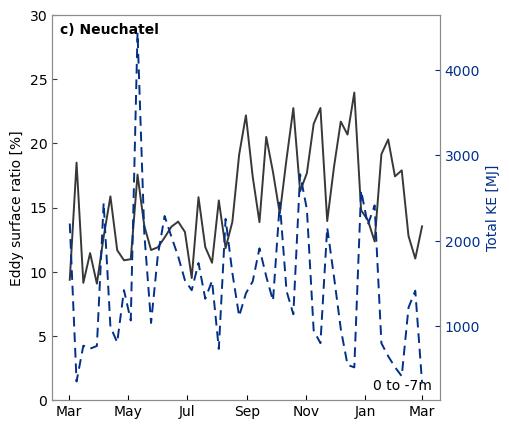

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))

ax.plot(
    surface_ratio_weekly.date,
    surface_ratio_weekly,
    color="#383838",
    lw=1.4,
    zorder=2
)

plt.ylim(bottom=0)    
plt.text(0.02, 0.98, f'{numbering} {lake.capitalize()}', transform=plt.gca().transAxes, ha='left', va='top', fontweight='bold')
plt.text(0.98, 0.02, f'{depth_max} to {depth_min}m', transform=plt.gca().transAxes, ha='right', va='bottom')


# --- Second y-axis: eddy surface ratio ---
ax2 = ax.twinx()

ke_by_depth_weekly = ke_by_depth.resample('1W').mean()
ax2.plot(
    ke_by_depth_weekly.index,
    ke_by_depth_weekly,
    color="#003088",
    lw=1.4,
    linestyle=(0, (5, 3)),
    zorder=3
)


if add_left_ylabel:
    ax.set_ylabel("Eddy surface ratio [%]")
    ax2.set_ylabel('')    
else:
    ax.set_ylabel('')    
ax2.set_ylabel("Total KE [MJ]", color="#003088")

ax.tick_params(axis='y', direction='in', color="#383838")
ax2.tick_params(axis='y', direction='in', colors="#003088")
ax.set_ylim(0,30)
#ax2.set_ylim(0,30)

ax.tick_params(axis='x', which='both', labelbottom=add_xlabel, direction='in')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

ax2.tick_params(axis='x', which='both', labelbottom=add_xlabel, direction='in')
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

plt.xlabel("")

# Same publication-style spine
for spine in ax2.spines.values():
    spine.set_color('#8B8B8B')
    spine.set_linewidth(0.8)

for spine in ax.spines.values():
    spine.set_color('#8B8B8B')
    spine.set_linewidth(0.8)

In [ ]:
depth_max, depth_min = 0, -7

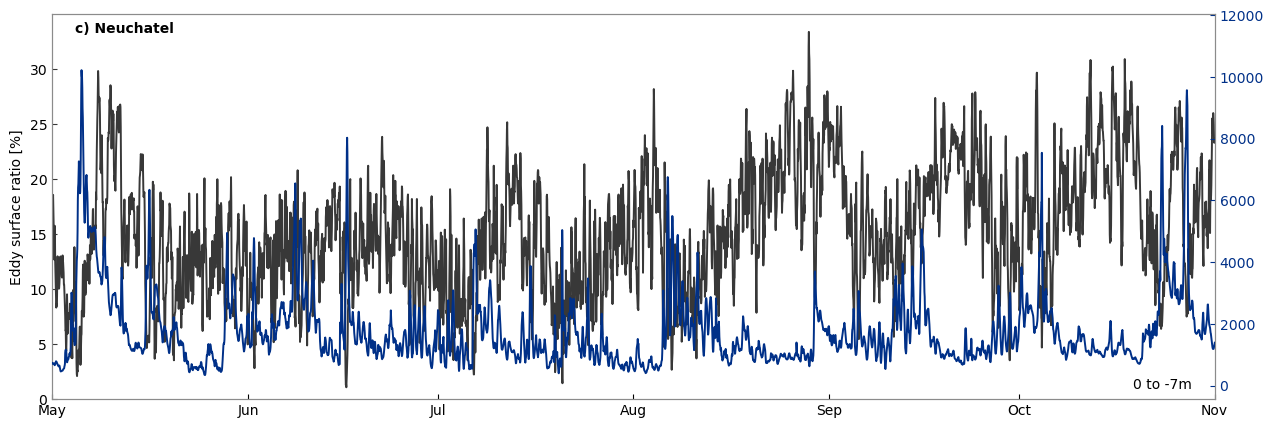

In [ ]:
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    ts_surface_ratio.date,
    ts_surface_ratio,
    color="#383838",
    lw=1.4,
    zorder=2
)

plt.ylim(bottom=0)    
plt.text(0.02, 0.98, f'{numbering} {lake.capitalize()}', transform=plt.gca().transAxes, ha='left', va='top', fontweight='bold')
plt.text(0.98, 0.02, f'{depth_max} to {depth_min}m', transform=plt.gca().transAxes, ha='right', va='bottom')


# --- Second y-axis: eddy surface ratio ---
ax2 = ax.twinx()

ke_by_depth_weekly = ke_by_depth.resample('1W').mean()
ax2.plot(
    ke_by_depth.index,
    ke_by_depth,
    color="#003088",
    lw=1.4,
    #linestyle=(0, (5, 3)),
    zorder=3
)


if add_left_ylabel:
    ax.set_ylabel("Eddy surface ratio [%]")
    ax2.set_ylabel('')    
else:
    ax.set_ylabel('')    
    ax2.set_ylabel("Total KE [MJ]", color="#003088")

ax.tick_params(axis='y', direction='in', color="#383838")
ax2.tick_params(axis='y', direction='in', colors="#003088")
#ax.set_ylim(10,35)
#ax2.set_ylim(100,600)

add_xlabel=True
ax.tick_params(axis='x', which='both', labelbottom=add_xlabel, direction='in')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

ax2.tick_params(axis='x', which='both', labelbottom=add_xlabel, direction='in')
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

plt.xlabel("")
plt.xlim(pd.to_datetime('2025-05-01'),pd.to_datetime('2025-11-01'))

# Same publication-style spine
for spine in ax2.spines.values():
    spine.set_color('#8B8B8B')
    spine.set_linewidth(0.8)

for spine in ax.spines.values():
    spine.set_color('#8B8B8B')
    spine.set_linewidth(0.8)

(-30.0, 30.0)

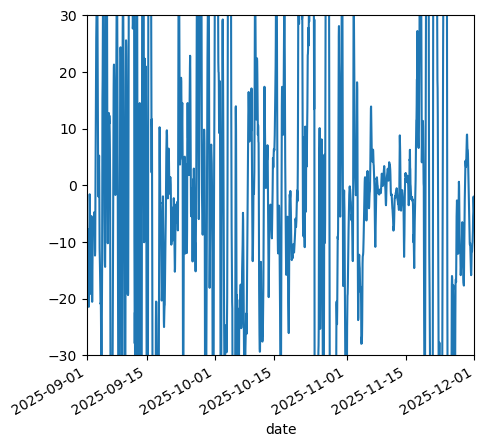

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))

ke_by_depth.diff().rolling(24).mean().plot()
plt.xlim(pd.to_datetime('2025-09-01'),pd.to_datetime('2025-12-01'))
plt.ylim(-30,30)


Best lag: -1
Maximum correlation: 0.24307832760583456


Text(0.02, 0.92, 'Best lag: -1h ')

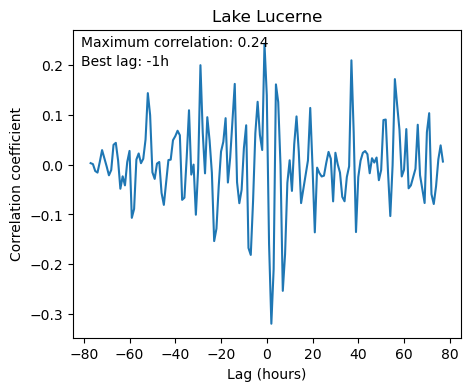

In [ ]:
from scipy.signal import correlate, correlation_lags

# Remove NaNs first if necessary
x_clean = wind_daily.sel(time=slice(pd.to_datetime('2025-09-15'), pd.to_datetime('2025-12-01'))).values
y_clean = ts_surface_ratio_daily.sel(date=slice(pd.to_datetime('2025-09-15'), pd.to_datetime('2025-12-01'))).values

# Remove means
x_clean = x_clean - np.mean(x_clean)
y_clean = y_clean - np.mean(y_clean)

# Cross-correlation
corr = correlate(y_clean, x_clean, mode="full")
lags = correlation_lags(len(y_clean), len(x_clean), mode="full")

# Normalize
corr = corr / (
    np.std(x_clean) * np.std(y_clean) * len(x_clean)
)

# Lag of maximum correlation
best_lag = lags[np.argmax(corr)]

print("Best lag:", best_lag)
print("Maximum correlation:", np.max(corr))
plt.figure(figsize=(5,4))
plt.plot(lags, corr)
#plt.xlim(-10, 20)
#plt.ylim(0.5,0.65)
plt.title(f'Lake {lake.capitalize()}')
plt.ylabel('Correlation coefficient')
plt.xlabel('Lag (hours)')
plt.text(0.02, 0.98, f'Maximum correlation: {np.max(corr):.2f} ', transform=plt.gca().transAxes, ha='left', va='top')
plt.text(0.02, 0.92, f'Best lag: {best_lag:.0f}h ', transform=plt.gca().transAxes, ha='left', va='top')